<a href="https://colab.research.google.com/github/zaaz-png/results/blob/main/fds8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
from google.colab import files
uploaed= files.upload()

df= pd.read_csv('cleaned_dataset2.csv')

Saving cleaned_dataset2.csv to cleaned_dataset2 (2).csv


Columns in dataset: ['Patient ID', 'Age', 'Blood Pressure', 'Urine Specific Gravity', 'Albumin in urine', 'Sugar in urine', 'RBC', 'Puss cells', 'Pus cells clumps', 'Bacteria', 'Random blood glucose', 'Urea in blood', 'Serum Creatinine', 'Sodium in blood', 'Potassium in blood', 'Hemoglobin', 'Packed corpuscular volume', 'WBC count', 'RBC count', 'Apetite', 'Chronic kidney failure']
Selected numerical columns for analysis: ['Age', 'Blood Pressure', 'Urine Specific Gravity', 'Albumin in urine', 'Sugar in urine', 'Random blood glucose']


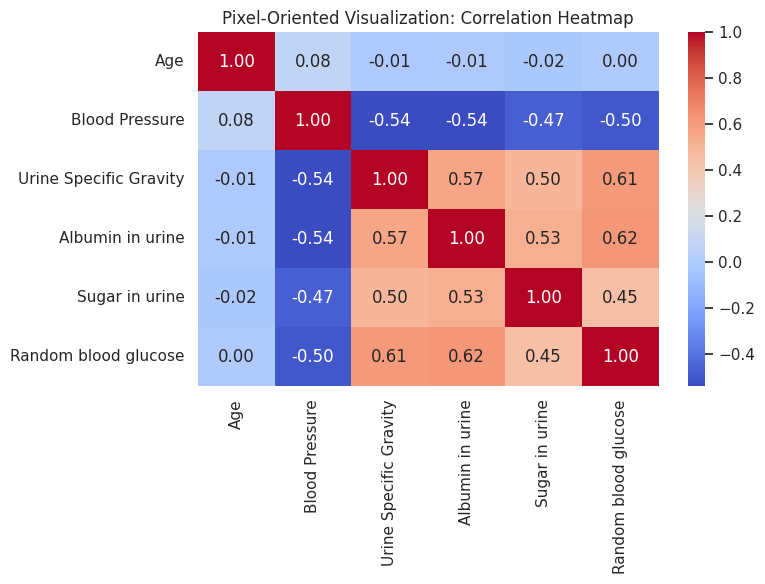

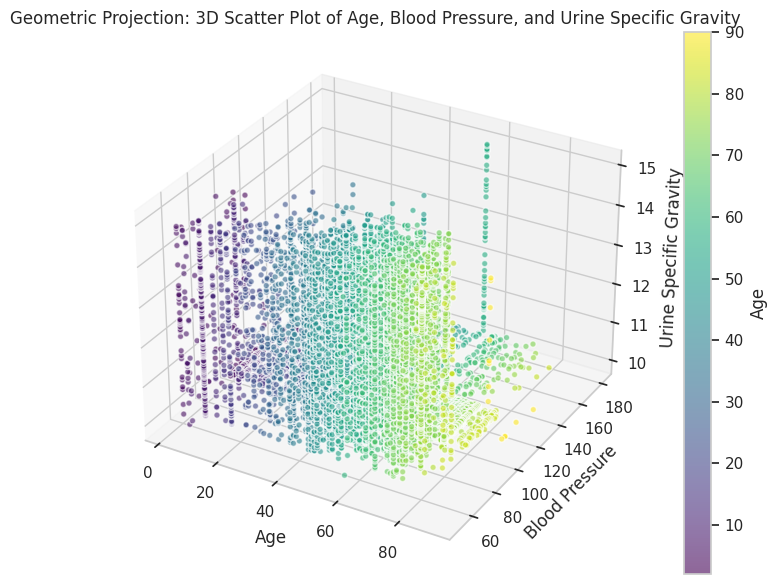

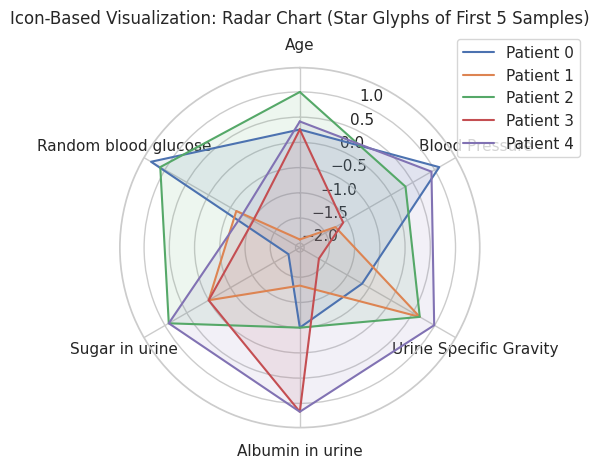

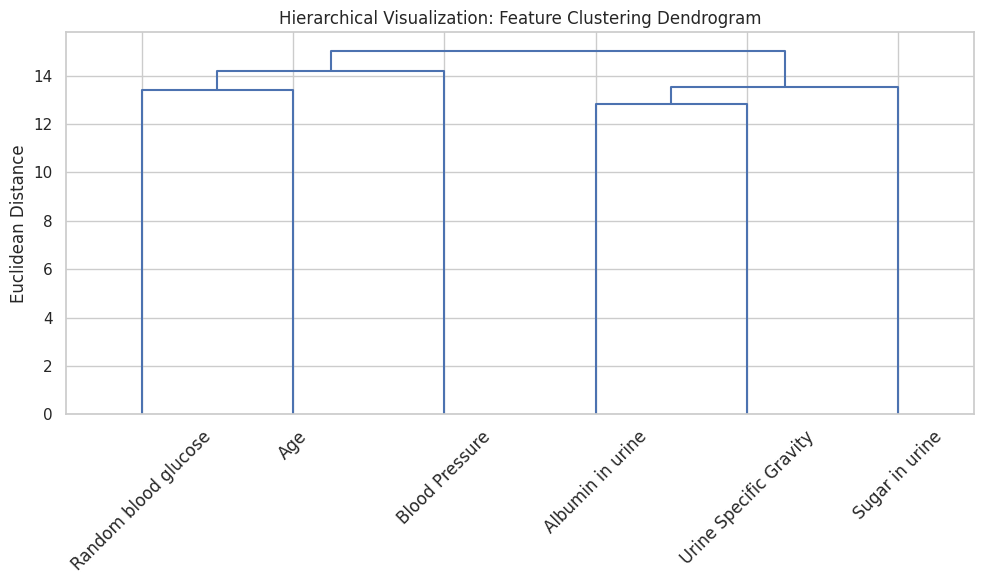

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.preprocessing import StandardScaler


# Print information about columns to select appropriate columns for plots
print("Columns in dataset:", df.columns.tolist())

# Select some continuous numerical columns for visualization
# Finding numerical columns
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
# Exclude 'Patient ID' or similar identifier if present
num_cols = [col for col in num_cols if 'id' not in col.lower()][:6]
print("Selected numerical columns for analysis:", num_cols)

# Handle missing values if any for plotting
plot_data = df[num_cols].dropna().head(100) # taking first 100 rows for neat visualizations like dendrogram

# Set style
sns.set_theme(style="whitegrid")


# 1. Pixel-Oriented Visualization: Heatmap

plt.figure(figsize=(8, 6))
correlation_matrix = df[num_cols].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Pixel-Oriented Visualization: Correlation Heatmap')
plt.tight_layout()
plt.show()

# 2. Geometric Projection Visualization: 3D Scatter Plot
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

x_col = num_cols[0]
y_col = num_cols[1]
z_col = num_cols[2]

scatter = ax.scatter(df[x_col], df[y_col], df[z_col], c=df[x_col], cmap='viridis', alpha=0.6, edgecolors='w')
ax.set_xlabel(x_col)
ax.set_ylabel(y_col)
ax.set_zlabel(z_col)
fig.colorbar(scatter, ax=ax, label=x_col)
plt.title(f'Geometric Projection: 3D Scatter Plot of {x_col}, {y_col}, and {z_col}')
plt.tight_layout()
plt.show()

# 3. Icon-Based Visualization: Radar Chart (Star Glyphs equivalent)
# -----------------------------------------------------
# Normalize data for radar chart to make it comparable
scaler = StandardScaler()
scaled_vals = scaler.fit_transform(plot_data.head(5))
labels = num_cols
num_vars = len(labels)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
for i in range(len(scaled_vals)):
    values = scaled_vals[i].tolist()
    values += values[:1]
    ax.plot(angles, values, label=f'Patient {plot_data.index[i]}')
    ax.fill(angles, values, alpha=0.1)

ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), labels)
plt.title('Icon-Based Visualization: Radar Chart (Star Glyphs of First 5 Samples)', y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

# 4. Hierarchical Visualization: Dendrogram
plt.figure(figsize=(10, 6))
# Performing hierarchical clustering on the transposed scaled subset to cluster features
scaled_features = scaler.fit_transform(plot_data)
linked = linkage(scaled_features.T, 'ward')

dendrogram(linked,
            orientation='top',
            labels=num_cols,
            distance_sort='descending',
            show_leaf_counts=True)
plt.title('Hierarchical Visualization: Feature Clustering Dendrogram')
plt.ylabel('Euclidean Distance')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()